# Does a Simple Trend Following Strategy Beat Buy and Hold?
### A moving average crossover backtest on SPY, with trading costs, an out of sample test, and checks on whether the result is just luck

**Matin Nikoomanzar**

**The question.** The 50/200 day moving average crossover (the "golden cross") is one of the oldest trend following rules around. Hold the S&P 500 when its 50 day average is above its 200 day average, sit in cash otherwise. Does that actually beat just buying and holding the index, after trading costs, on years it wasn't tuned on?

**What I did.**
1. Got about 26 years of dividend adjusted SPY prices.
2. Split them. 2000 to 2017 is in sample, used to pick the windows. 2018 to now is out of sample, and I only look at it once at the end.
3. Tried a small grid of window pairs on the in sample years only.
4. Froze the winner and tested it out of sample with a 5 bps cost every time the position changes.
5. Then asked how much to trust that one test, using a wider parameter sweep, a walk forward test, a bootstrap, the deflated Sharpe ratio and the probability of backtest overfitting.

**Short answer.** No. The rule lost to buy and hold out of sample, and the later checks show that picking the "best" windows from history was no better than a coin flip.

**Update.** I later found two bugs in my first version (section 7) and fixed them, so the numbers here are a bit different from the first write up. The conclusion didn't change. This notebook is the first study. The bigger follow up, which asks whether trend following is worth it as protection across a century and several asset classes, is in `run_study.py` and `paper/`.

In [1]:
import warnings
warnings.filterwarnings("ignore", message=".*OpenSSL.*")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import backtest_core as bc   # strategy, costs and metrics
import robustness as rb      # the luck checks in section 6

plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["axes.grid"] = True

COST_BPS = 5.0            # 0.05% per side, roughly an ETF spread plus slippage
DELAY = 1                 # days between the signal close and the trade
SPLIT_DATE = "2018-01-01" # before is in sample, after is out of sample

## 1. Data

Daily dividend adjusted closes for SPY since 2000. Adjusted prices matter. Without dividends, buy and hold looks about 2% a year worse than it really was, which would make the strategy look better than it is. The prices are cached in `spy_prices.csv` so every run gives the same numbers.

Full sample:   2000-01-03 to 2026-06-10  (6649 days)
In sample:     2000-01-03 to 2017-12-29  (4528 days)
Out of sample: 2018-01-02 to 2026-06-10  (2121 days)
T-bills paid 65% in total over the full sample


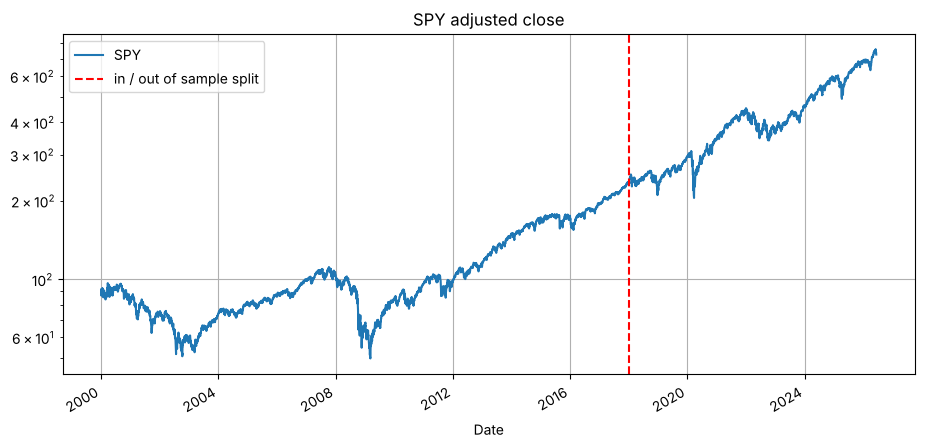

In [2]:
prices = bc.load_prices("SPY", start="2000-01-01", cache_path="spy_prices.csv")
rf = bc.load_rf(prices.index)  # daily T-bill return, what cash earns (Ken French file)

in_sample  = prices[prices.index <  SPLIT_DATE]
out_sample = prices[prices.index >= SPLIT_DATE]

print(f"Full sample:   {prices.index[0].date()} to {prices.index[-1].date()}  ({len(prices)} days)")
print(f"In sample:     {in_sample.index[0].date()} to {in_sample.index[-1].date()}  ({len(in_sample)} days)")
print(f"Out of sample: {out_sample.index[0].date()} to {out_sample.index[-1].date()}  ({len(out_sample)} days)")
print(f"T-bills paid {(1 + rf).prod() - 1:.0%} in total over the full sample")

prices.plot(title="SPY adjusted close", logy=True)
plt.axvline(pd.Timestamp(SPLIT_DATE), color="red", ls="--", label="in / out of sample split")
plt.legend(); plt.show()

## 2. The rule, and the usual ways backtests cheat

**Rule.** Long SPY when the fast average is above the slow one, cash otherwise.

**Lookahead.** The averages use today's close, so the earliest you could trade on them is tomorrow's close. The return from tomorrow's close to the day after is the first one the strategy earns, so `ma_crossover_positions` shifts the signal by two days. My first version only shifted by one, which quietly traded at the same close the signal came from.

**Cash.** When the rule is out of the market the money sits in T-bills and earns the T-bill rate (the daily risk free return from the Ken French data library). My first version gave cash 0%. Sharpe ratios here are measured over T-bills too.

**Free trading.** Every position change pays 5 bps, so a round trip costs 10 bps. This rule barely trades, so the cost is small, but it should still be in the numbers.

**Cold start.** The averages need 200 days of history. If you start computing them on the first test day, the strategy sits in cash for most of 2018 for no real reason. My first version did exactly that. Now the signal is built on the full history and then sliced at the split, so it's already warmed up on day one of the test.

## 3. Picking the windows, in sample only

A small grid of (fast, slow) pairs on 2000 to 2017, ranked by Sharpe. The test years play no part in this.

In [3]:
FAST_GRID = [20, 50, 100]
SLOW_GRID = [100, 150, 200, 250]

grid = bc.grid_search(in_sample, FAST_GRID, SLOW_GRID, cost_bps=COST_BPS, rf=rf, delay=DELAY)
grid.round(3)

,fast,slow,sharpe,cagr,max_dd,trades
0,20,200,0.677,0.085,-0.173,25
1,50,200,0.649,0.084,-0.202,19
2,50,250,0.648,0.083,-0.198,11
3,20,250,0.589,0.076,-0.210,19
4,100,250,0.575,0.076,-0.217,9
5,50,150,0.570,0.075,-0.185,27
6,100,150,0.489,0.067,-0.220,31
7,100,200,0.477,0.065,-0.186,15
8,50,100,0.447,0.061,-0.220,39
9,20,150,0.366,0.050,-0.236,43


In [4]:
best = grid.iloc[0]
FAST, SLOW = int(best["fast"]), int(best["slow"])
print(f"Picked: fast={FAST}, slow={SLOW}  (frozen from here on)")
print(f"In sample Sharpe: {best['sharpe']:.2f}  |  trades: {best['trades']}")

Picked: fast=20, slow=200  (frozen from here on)
In sample Sharpe: 0.68  |  trades: 25.0


Even this small search is a bit of data mining. With 11 pairs, the winner partly won by luck. Section 6 tries to measure how much. It's also a little telling that once I fixed the two bugs, the winner moved from 50/200 to 20/200, with 50/200 a close second. The ranking is that fragile.

## 4. Out of sample

The frozen rule on 2018 to now, data it never saw.

In [5]:
pos_full = bc.ma_crossover_positions(prices, FAST, SLOW, DELAY)  # warmed up on all history
results_full = bc.run_backtest(prices, pos_full, cost_bps=COST_BPS, rf=rf)

results_oos = results_full[results_full.index >= SPLIT_DATE]
results_ins = results_full[results_full.index <  SPLIT_DATE]
pos_oos = pos_full[pos_full.index >= SPLIT_DATE]

summary_oos = bc.summarize(results_oos, rf=rf)
summary_oos.round(3)

,strategy,buy_hold
CAGR,0.097,0.143
Annual Vol,0.147,0.192
Sharpe,0.528,0.661
Max Drawdown,-0.300,-0.337


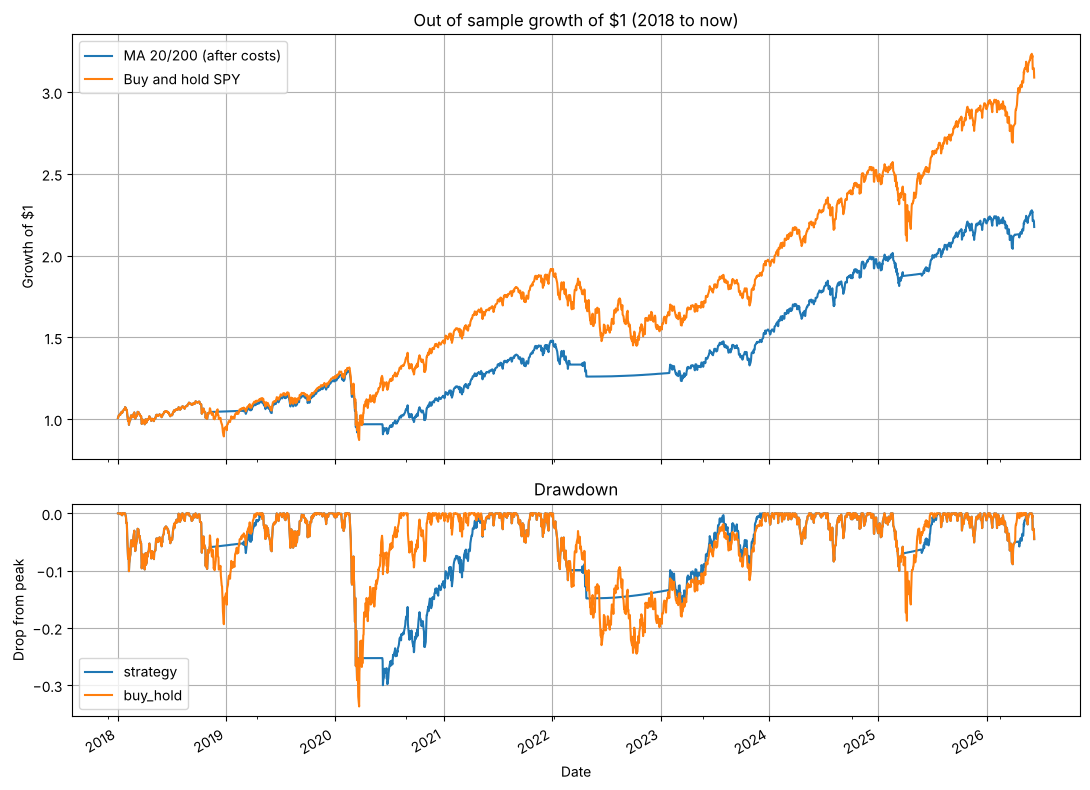

In [6]:
equity = (1 + results_oos).cumprod()

fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True,
                         gridspec_kw={"height_ratios": [2, 1]})
equity["strategy"].plot(ax=axes[0], label=f"MA {FAST}/{SLOW} (after costs)")
equity["buy_hold"].plot(ax=axes[0], label="Buy and hold SPY")
axes[0].set_title("Out of sample growth of $1 (2018 to now)")
axes[0].set_ylabel("Growth of $1"); axes[0].legend()
for col in equity:
    (equity[col] / equity[col].cummax() - 1).plot(ax=axes[1], label=col)
axes[1].set_title("Drawdown"); axes[1].set_ylabel("Drop from peak"); axes[1].legend()
plt.tight_layout(); plt.show()

In [7]:
n_trades = int(pos_oos.diff().abs().sum())
print(f"Out of sample trades: {n_trades}")
print(f"Time invested: {pos_oos.mean():.0%} of days")
print(f"Total cost drag: about {n_trades * COST_BPS / 100:.2f}% of capital")

Out of sample trades: 14
Time invested: 81% of days
Total cost drag: about 0.70% of capital


## 5. In sample vs out of sample

In [8]:
comparison = pd.concat(
    {"In sample (2000 to 2017)": bc.summarize(results_ins, rf=rf),
     "Out of sample (2018 on)": summary_oos},
    axis=1,
)
comparison.round(3)

In sample (2000 to 2017)          Out of sample (2018 on)  \
                             strategy buy_hold                strategy   
CAGR                            0.085    0.054                   0.097   
Annual Vol                      0.106    0.194                   0.147   
Sharpe                          0.677    0.287                   0.528   
Max Drawdown                   -0.173   -0.552                  -0.300   

                       
             buy_hold  
CAGR            0.143  
Annual Vol      0.192  
Sharpe          0.661  
Max Drawdown   -0.337

In sample the rule beat buy and hold on every metric. Out of sample it only won on volatility and a slightly smaller worst drawdown. The gap between the two columns is a first measure of overfitting, but it's one number from one split. The next section looks harder.

## 6. Is the result real, or luck?

One out of sample test can still mislead, in either direction. Maybe 2018 to 2026 just happened to be a bad stretch for trend following, or maybe the picked windows were a lucky pick. These checks look at it from a few angles. The code is in `robustness.py`.

### 6.1 Every window pair, including the ones I passed over

89 pairs, fast from 10 to 100 and slow from 100 to 300. If the picked pair were special, nearby pairs should do about as well, and pairs that did well in sample should keep doing well out of sample.

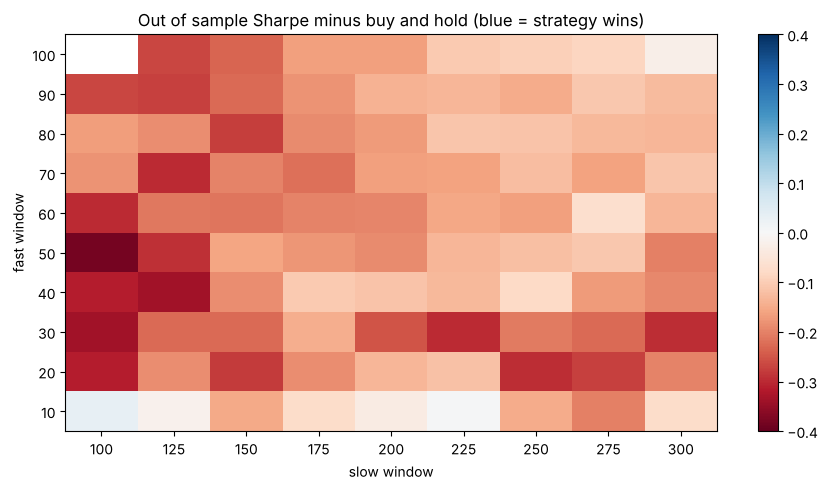

Pairs that beat buy and hold out of sample: 2 of 89
Correlation between in sample and out of sample Sharpe: 0.37


In [9]:
F_LIST = list(range(10, 101, 10))
S_LIST = list(range(100, 301, 25))
sens = rb.sensitivity_grid(prices, SPLIT_DATE, F_LIST, S_LIST, COST_BPS, rf=rf, delay=DELAY)

heat = sens.pivot(index="fast", columns="slow", values="sharpe_out") - sens["bh_out"].iloc[0]
fig, ax = plt.subplots(figsize=(9, 5))
im = ax.imshow(heat.values, cmap="RdBu", vmin=-0.4, vmax=0.4, aspect="auto", origin="lower")
ax.set_xticks(range(len(heat.columns)), heat.columns); ax.set_yticks(range(len(heat.index)), heat.index)
ax.set_xlabel("slow window"); ax.set_ylabel("fast window"); ax.grid(False)
ax.set_title("Out of sample Sharpe minus buy and hold (blue = strategy wins)")
plt.colorbar(im, ax=ax); plt.tight_layout(); plt.savefig("figures/sensitivity.png", dpi=150); plt.show()

rho = np.corrcoef(sens["sharpe_in"], sens["sharpe_out"])[0, 1]
print(f"Pairs that beat buy and hold out of sample: {sens['beats_bh_out'].sum()} of {len(sens)}")
print(f"Correlation between in sample and out of sample Sharpe: {rho:.2f}")

Almost the whole map is red. Only two pairs beat buy and hold out of sample. The in sample ranking predicts the out of sample one a little (correlation about 0.37), but not enough to pick a winner.

### 6.2 Walk forward

A single split is a bit artificial. Here, every January I pick the best pair using only the years before it, hold it for that year, and repeat. That starts in 2008, so it also includes the financial crisis.

              walk forward  buy and hold
CAGR                 0.077         0.111
Sharpe               0.516         0.564
Max drawdown        -0.337        -0.519

Pairs it picked: {'30/225': 10, '10/200': 3, '40/250': 3, '40/225': 2, '30/275': 1}


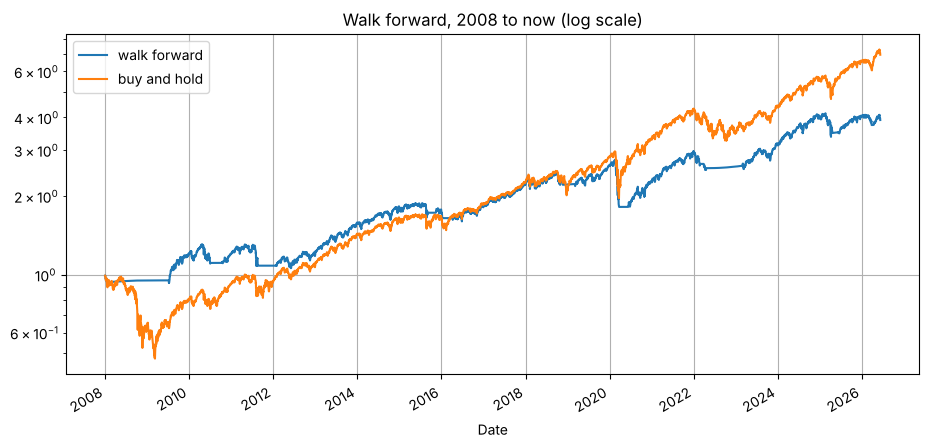

In [10]:
picks, wf, bh_wf = rb.walk_forward(prices, F_LIST, S_LIST, first_year=2008, cost_bps=COST_BPS, rf=rf, delay=DELAY)
print(pd.DataFrame({"walk forward": [bc.cagr(wf), bc.sharpe(wf, rf=rf), bc.max_drawdown(wf)],
                    "buy and hold": [bc.cagr(bh_wf), bc.sharpe(bh_wf, rf=rf), bc.max_drawdown(bh_wf)]},
                   index=["CAGR", "Sharpe", "Max drawdown"]).round(3))
print("\nPairs it picked:", picks["pick"].value_counts().to_dict())

ax = (1 + pd.DataFrame({"walk forward": wf, "buy and hold": bh_wf})).cumprod().plot(logy=True)
ax.set_title("Walk forward, 2008 to now (log scale)"); plt.show()

With 2008 in the window the rule does better on risk. Its worst drawdown is about 34% against 52% for buy and hold, and its Sharpe is a bit lower but close (0.52 against 0.56). It still grows a lot less money, 7.7% a year against 11.1%. So trend following isn't useless. It acts like insurance, and you pay for it in the good years.

### 6.3 Bootstrap: how sure can one test period be?

I resample the test period in random blocks (a stationary bootstrap, average block of 20 days, so calm and wild stretches stay together) and recompute the Sharpe gap 2,000 times.

Sharpe gap (strategy minus buy and hold): -0.12
95% interval: -0.49 to 0.29
Share of resamples where the strategy wins: 28%


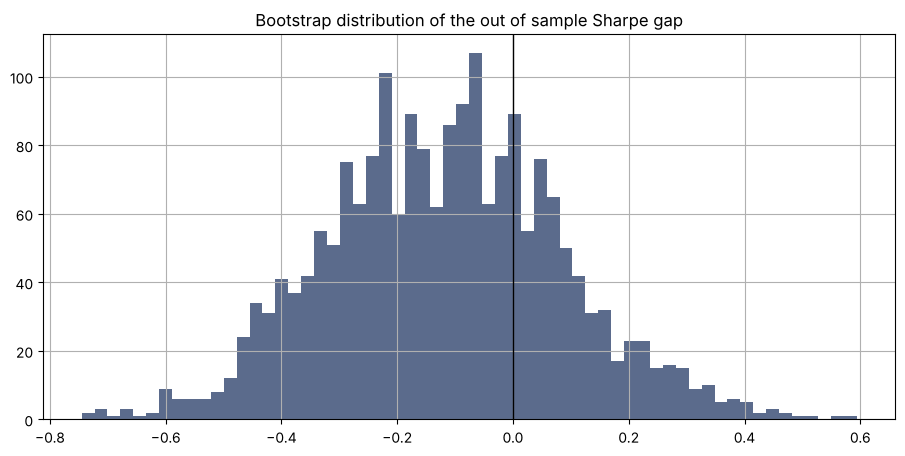

In [11]:
diff = rb.bootstrap_sharpe_diff(results_oos["strategy"], results_oos["buy_hold"], n_boot=2000, seed=0,
                                rf=rf.reindex(results_oos.index))
lo, hi = np.percentile(diff, [2.5, 97.5])
print(f"Sharpe gap (strategy minus buy and hold): {diff.mean():.2f}")
print(f"95% interval: {lo:.2f} to {hi:.2f}")
print(f"Share of resamples where the strategy wins: {(diff > 0).mean():.0%}")

plt.hist(diff, bins=60, color="#5B6B8C"); plt.axvline(0, color="k", lw=1)
plt.title("Bootstrap distribution of the out of sample Sharpe gap"); plt.savefig("figures/bootstrap.png", dpi=150); plt.show()

The interval includes zero. So eight and a half years isn't enough to say for sure the strategy is worse on a risk adjusted basis. It just isn't better, and in about three out of four resamples it loses.

### 6.4 Deflated Sharpe ratio

When you try a bunch of rules and keep the best one, its Sharpe is inflated just from the trying. The deflated Sharpe ratio (Bailey and Lopez de Prado, 2014) asks how likely the winner's true Sharpe is above zero once you account for the number of rules tried and for fat tails.

In [12]:
for name, pairs in [("small grid (11 pairs)", rb.make_pairs(FAST_GRID, SLOW_GRID)),
                    ("big grid (89 pairs)", rb.make_pairs(F_LIST, S_LIST))]:
    R_in = rb.returns_matrix(prices, pairs, COST_BPS, rf, DELAY).sub(rf, axis=0)  # returns over T-bills
    R_in = R_in[R_in.index < SPLIT_DATE]
    daily_sr = R_in.mean() / R_in.std()
    winner = daily_sr.idxmax()
    d = rb.deflated_sharpe(R_in[winner], daily_sr.values)
    print(f"{name}: winner {winner}, deflated Sharpe probability {d['dsr']:.3f}")

small grid (11 pairs): winner 20/200, deflated Sharpe probability 0.980


big grid (89 pairs): winner 30/225, deflated Sharpe probability 0.977


Even after deflating, the in sample winner very likely had a real positive Sharpe. That's not a surprise, since being in the stock market most of the time makes money. The real question is whether it beats just holding, and that's what the next check is about.

### 6.5 Probability of backtest overfitting

This one is from Bailey, Borwein, Lopez de Prado and Zhu (2017). Cut 2000 to 2017 into 16 chunks. For every way of choosing 8 of them as a pretend in sample (12,870 ways), pick the best of the 89 pairs there and check where it ranks on the other 8. PBO is the share of times the winner lands in the bottom half. 0 would mean picking the best works every time, 0.5 means it's no better than picking at random.

PBO: 0.63  (12,870 splits)


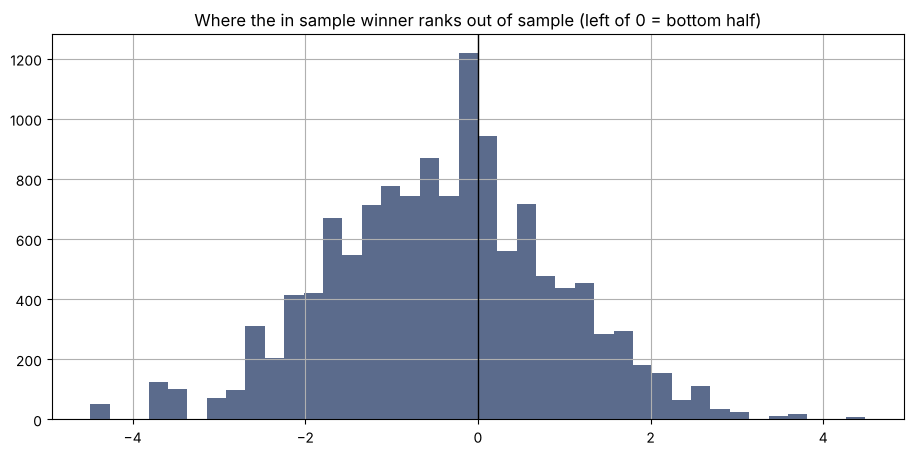

In [13]:
R_big = rb.returns_matrix(prices, rb.make_pairs(F_LIST, S_LIST), COST_BPS, rf, DELAY).sub(rf, axis=0)
p = rb.pbo_cscv(R_big[R_big.index < SPLIT_DATE], n_blocks=16)
print(f"PBO: {p['pbo']:.2f}  ({p['n_splits']:,} splits)")

plt.hist(p["logits"], bins=40, color="#5B6B8C"); plt.axvline(0, color="k", lw=1)
plt.title("Where the in sample winner ranks out of sample (left of 0 = bottom half)")
plt.savefig("figures/pbo.png", dpi=150); plt.show()

About 0.63. Picking the best looking windows from history did worse than picking at random. That's the clearest sign the "edge" from tuning was noise.

### 6.6 Costs

In [14]:
rb.cost_sensitivity(prices, SPLIT_DATE, FAST, SLOW, rf=rf, delay=DELAY).round(3)

,cost_bps,sharpe_out,bh_out
0,0,0.534,0.661
1,5,0.528,0.661
2,10,0.523,0.661
3,20,0.511,0.661
4,50,0.477,0.661


Costs barely matter here because the rule only trades a handful of times. Going from 0 to 50 bps a trade moves the Sharpe from 0.53 to 0.48. That rules out costs as the reason it lost.

## 7. What the two bug fixes did

This notebook used to have two mistakes. The position was shifted by one day, but with close to close returns that means it traded at the same close the signal came from, not the next one. And cash earned nothing. The cell below runs the rule three ways so you can see what each fix changed.

In [15]:
# what the two fixes did to the out of sample numbers, saved so the README can quote them
import json

def oos(delay, cash):
    pos = bc.ma_crossover_positions(prices, 50, 200, delay)
    res = bc.run_backtest(prices, pos, COST_BPS, rf if cash else None)
    res = res[res.index >= SPLIT_DATE]
    r, b = res["strategy"], res["buy_hold"]
    return {"cagr": bc.cagr(r), "sharpe": bc.sharpe(r, rf=rf if cash else None),
            "max_dd": -bc.max_drawdown(r), "growth_of_1": float((1 + r).prod()),
            "bh_cagr": bc.cagr(b), "bh_sharpe": bc.sharpe(b, rf=rf if cash else None),
            "bh_max_dd": -bc.max_drawdown(b), "bh_growth_of_1": float((1 + b).prod())}

steps = {"old: trade at the signal close, cash earns 0": oos(0, False),
         "cash earns T-bills": oos(0, True),
         "and trade at the next close (current)": oos(1, True)}
print(pd.DataFrame(steps).round(3).to_string())

spy = {"split": SPLIT_DATE, "picked": f"{FAST}/{SLOW}", "fix_steps": steps,
       "pairs_beating_bh_out": int(sens["beats_bh_out"].sum()), "n_pairs": len(sens), "rho_in_out": float(rho),
       "walk_forward": {"cagr": bc.cagr(wf), "sharpe": bc.sharpe(wf, rf=rf), "max_dd": -bc.max_drawdown(wf),
                        "bh_cagr": bc.cagr(bh_wf), "bh_sharpe": bc.sharpe(bh_wf, rf=rf), "bh_max_dd": -bc.max_drawdown(bh_wf)},
       "bootstrap_sharpe_gap": {"mean": float(diff.mean()), "lo95": float(lo), "hi95": float(hi),
                                "share_strategy_wins": float((diff > 0).mean())},
       "pbo": p["pbo"]}
with open("results/spy_study.json", "w") as f:
    json.dump(spy, f, indent=1, default=float)

                old: trade at the signal close, cash earns 0  cash earns T-bills  and trade at the next close (current)
cagr                                                   0.092               0.096                                  0.093
sharpe                                                 0.626               0.493                                  0.474
max_dd                                                 0.337               0.337                                  0.337
growth_of_1                                            2.101               2.170                                  2.119
bh_cagr                                                0.143               0.143                                  0.143
bh_sharpe                                              0.794               0.661                                  0.661
bh_max_dd                                              0.337               0.337                                  0.337
bh_growth_of_1                          

The fixed rule ends up close to where it started. Cash interest added about 0.4 points a year, and trading one day later took about 0.3 back, so the 50/200 rule went from 9.2% a year to 9.3% (growth of $1 from $2.10 to $2.12, against $3.09 for SPY). The Sharpe ratios drop a lot, but that's mostly because they are now measured over T-bills instead of over zero, which is the right way, and it hits buy and hold just as hard (0.79 to 0.66). The worst drawdown is the same 33.7% in all three versions because the rule was still invested at the bottom in March 2020.

## 8. What I take from this

1. **It lost out of sample.** The rule picked in sample (20/200 after the fixes) made 9.7% a year against 14.3% for buy and hold, with a Sharpe over T-bills of 0.53 against 0.66. Lower volatility and a slightly smaller worst drawdown (30% against 34%), but the COVID crash in 2020 was too fast for a 200 day average. It got out near the bottom and missed part of the rebound.

2. **The tuning was mostly noise.** Only 2 of 89 window pairs beat buy and hold out of sample, the in sample ranking only weakly predicted the out of sample one, and the probability of backtest overfitting was about 0.63. Fixing two small bugs was enough to change which pair "won".

3. **But it isn't worthless.** In a walk forward test that includes 2008, the worst drawdown was much smaller than buy and hold's and the bootstrap interval for the Sharpe gap includes zero. It behaves like insurance. It helps in slow crashes, it costs you in bull markets, and it can't react to fast crashes.

### Limitations
- **One asset and one stretch of history, looked at many times.** That's why the follow up study tests the rule on data I hadn't touched (US stocks before 2000 and other markets) with a protocol written down first. See `docs/protocol.md` and `paper/`.
- **Execution is simple.** Fills at the close, flat 5 bps, no taxes. Taxes alone could wipe out any edge for a taxable account.

### What I learned
Most of the work in a backtest is making sure it isn't lying to you. Lookahead, costs, cold starts and picking the best of many rules all make results look better than they are, and each one had to be found and fixed on purpose. I found two of those bugs in my own first version, one of them after I thought I was done.